# Paso 13 · Muestreo por eventos con periodo base $T$ (con Python)

Notebook del **Paso 13**: enviar la medida solo cuando cambia más que un umbral $\delta$. Cuánto se ahorra, cuánto se paga y por qué QFT lo trata como ruido acotado (umbral absoluto) o como incertidumbre multiplicativa (umbral relativo).

| Concepto matemático | Concepto de programación |
|---|---|
| disparador $|y_k-\hat y|>\delta+\sigma|y_k|$ | simulación con estado y *flags* de evento |
| cota $|\Delta y|\le\delta\,\|t\|_1$ | suma de la respuesta al impulso (`signal.dimpulse`) |
| ahorro de envíos frente a error | barrido de $\delta$ y tabla |
| $L\to L(1+\Delta)$, $|\Delta|\le\sigma$ | muestreo del disco de incertidumbre |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from scipy import signal
from nbhelp import db, AZUL, NARANJA, TINTA, GRIS, VERDE
from qft import KS, AS

Ts = 0.04                                   # periodo base T (el del paso 12)
nG, dG, _ = signal.cont2discrete(([5.2*28/2.6, 5.2*28], [1, 28]), Ts, method="bilinear"); nG = nG.ravel()   # G(z) del paso 12
nF, dF, _ = signal.cont2discrete(([1.2], [1, 1.2]), Ts, method="bilinear"); nF = nF.ravel()               # F(z)

def planta(K, a):
    A = np.array([[0, 1], [0, -a]]); B = np.array([[0], [K]]); Cm = np.array([[1, 0]])
    return signal.cont2discrete((A, B, Cm, [[0]]), Ts, method="zoh")[:3]

## 1. Qué es muestrear por eventos con periodo base $T$

Un reloj de periodo $T$ despierta al sensor. Éste compara $y_k$ con la **última medida enviada** $\hat y$: si $|y_k-\hat y|>\delta$, **envía** ($\hat y\leftarrow y_k$); si no, **calla**. El controlador usa siempre $\hat y$ (retención). Entre envíos hay al menos $T$ segundos: no hay comportamiento de Zenón.

Un simulador completo del lazo (con $G(z)$, $F(z)$ y la planta del Paso 12):

In [3]:
def sim(K, a, r, delta=0.0, sigma=0.0, d=0.0, hb=10**9, umax=1e9, dist_t=0):
    """Lazo con muestreo por eventos. Dispara si |y_k - yhat| > delta + sigma|y_k| o pasan hb muestras sin envío."""
    Ad, Bd, Cd = planta(K, a); N = len(r)
    x = np.zeros((2, 1)); y = np.zeros(N); yh = np.zeros(N); u = np.zeros(N); ev = np.zeros(N, bool)
    rf_p = r_p = e_p = u_p = 0.0; yhat = 0.0; ultimo = 0
    for k in range(N):
        yk = float((Cd @ x)[0, 0])
        if k == 0 or abs(yk - yhat) > delta + sigma*abs(yk) or (k - ultimo) >= hb:
            yhat = yk; ev[k] = True; ultimo = k
        rf = -dF[1]*rf_p + nF[0]*(r[k] + r_p); e = rf - yhat
        us = float(np.clip(-dG[1]*u_p + nG[0]*e + nG[1]*e_p, -umax, umax))
        y[k] = yk; yh[k] = yhat; u[k] = us; x = Ad @ x + Bd*(us + (d if k >= dist_t else 0.0)); rf_p, r_p, e_p, u_p = rf, r[k], e, us
    return y, yh, u, ev

N = int(8/Ts); r = np.ones(N); tt = np.arange(N)*Ts
y0, _, u0, _ = sim(5, 1, r)
y, yh, u, ev = sim(5, 1, r, delta=0.05)
print(f"δ = 0.05: {ev.sum()} envíos de {N} muestras (esquina K=5, a=1)")

δ = 0.05: 33 envíos de 200 muestras (esquina K=5, a=1)


## 2. La idea clave: el silencio es un error de medida

$e_k=\hat y_k-y_k$ cumple $|e_k|\le\delta$ por construcción. El controlador cree medir $y+e$: **ruido de medida acotado**. La salida es $y=T\,F\,r-T\,e$ y por tanto
$$|\Delta y_k|\le\delta\,\|t\|_1,\qquad \|t\|_1=\sum_k|t_k|\ \text{(respuesta al impulso de }T(z)).$$
Calculamos $\|t\|_1$ en las cuatro esquinas de la familia:

In [4]:
def norma1_T(K, a, n=3000):
    nP, dP, _ = signal.cont2discrete(([K], [1, a, 0]), Ts, method="zoh"); nP = nP.ravel()
    num = np.polymul(nG, nP); den = np.polyadd(np.polymul(dG, dP), num)     # T = L/(1+L)
    h = np.squeeze(signal.dimpulse((num, den, Ts), n=n)[1])
    return np.abs(h).sum()

esq = [(1, 1), (1, 3), (5, 1), (5, 3)]
n1 = {c: norma1_T(*c) for c in esq}
for c, v in n1.items(): print(f"‖t‖₁ en (K,a) = {c}: {v:.3f}")
L1 = max(n1.values()); print(f"peor caso: ‖t‖₁ = {L1:.3f}   (diapositivas: 1.42)")

‖t‖₁ en (K,a) = (1, 1): 1.340
‖t‖₁ en (K,a) = (1, 3): 1.000
‖t‖₁ en (K,a) = (5, 1): 1.424
‖t‖₁ en (K,a) = (5, 3): 1.117
peor caso: ‖t‖₁ = 1.424   (diapositivas: 1.42)


## 3. Cuánto se ahorra y cuánto se paga

In [5]:
sim0 = {c: sim(*c, r)[0] for c in esq}
print(f"{'δ':>6} {'envíos (de '+str(N)+')':>16} {'desv. máx. real':>16} {'cota δ‖t‖₁':>12}")
tab = []
for dl in (0, 0.01, 0.02, 0.05, 0.1, 0.2):
    env = []; dev = []
    for c in esq:
        yy, _, _, e = sim(*c, r, delta=dl); env.append(e.sum()); dev.append(np.abs(yy - sim0[c]).max())
    tab.append((dl, np.mean(env), max(dev)))
    print(f"{dl:>6} {np.mean(env):>16.0f} {max(dev):>16.4f} {dl*L1:>12.4f}")
assert all(d <= dl*L1 + 1e-9 for dl, _, d in tab)
print("\nLa desviación real queda siempre por debajo de la cota: es una garantía de peor caso.")

     δ  envíos (de 200)  desv. máx. real   cota δ‖t‖₁
     0              200           0.0000       0.0000
  0.01               57           0.0091       0.0142
  0.02               42           0.0188       0.0285
  0.05               27           0.0469       0.0712
   0.1               19           0.1048       0.1424
   0.2               18           0.1877       0.2848

La desviación real queda siempre por debajo de la cota: es una garantía de peor caso.


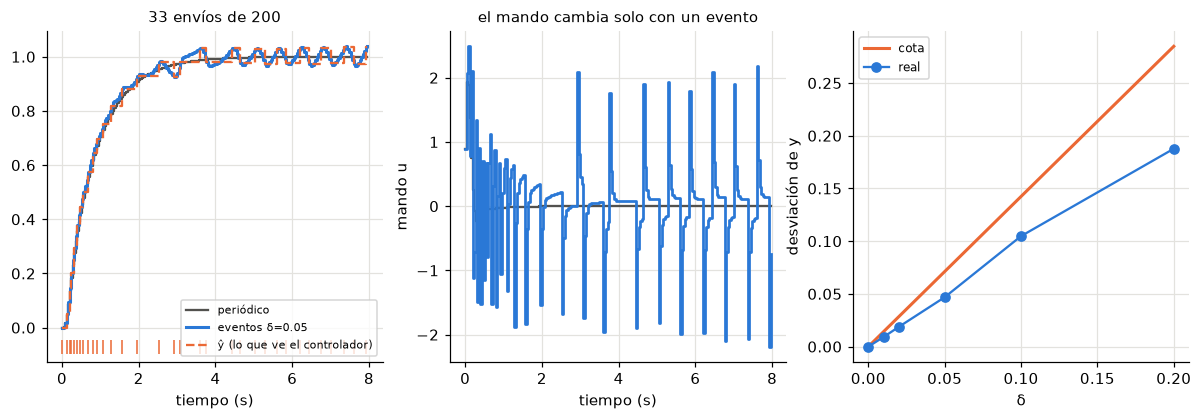

salto del mando por evento ≈ G(∞)·δ = 37.76·0.05 = 1.89


In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13.4, 3.9))
a = axs[0]; a.step(tt, y0, where="post", color=GRIS, label="periódico"); a.step(tt, y, where="post", color=AZUL, lw=2, label="eventos δ=0.05")
a.step(tt, yh, where="post", color=NARANJA, ls="--", label="ŷ (lo que ve el controlador)"); a.plot(tt[ev], np.full(ev.sum(), -0.07), "|", color=NARANJA, ms=9)
a.set_xlabel("tiempo (s)"); a.legend(fontsize=7.5, loc="lower right"); a.set_title(f"{ev.sum()} envíos de {N}", fontsize=10)
b = axs[1]; b.step(tt, u0, where="post", color=GRIS); b.step(tt, u, where="post", color=AZUL, lw=1.8); b.set_xlabel("tiempo (s)"); b.set_ylabel("mando u")
b.set_title("el mando cambia solo con un evento", fontsize=10)
c = axs[2]; D = [t[0] for t in tab]
c.plot(D, np.array(D)*L1, color=NARANJA, lw=2, label="cota"); c.plot(D, [t[2] for t in tab], "o-", color=AZUL, label="real")
c.set_xlabel("δ"); c.set_ylabel("desviación de y"); c.legend(fontsize=8); plt.show()
print(f"salto del mando por evento ≈ G(∞)·δ = {nG[0]:.2f}·0.05 = {nG[0]*0.05:.2f}")

## 4. Cómo elegir $\delta$ con una especificación

$\delta\le\Delta_y/\|t\|_1$ y, si hay límite de mando por evento, $\delta\le\Delta_u/G(\infty)$.

In [7]:
Dy, Du = 0.02, 1.0
print(f"Δy = {Dy}  ->  δ ≤ {Dy/L1:.3f}\nΔu = {Du}  ->  δ ≤ {Du/nG[0]:.3f}\nmanda el más restrictivo: δ ≤ {min(Dy/L1, Du/nG[0]):.3f}")

Δy = 0.02  ->  δ ≤ 0.014
Δu = 1.0  ->  δ ≤ 0.026
manda el más restrictivo: δ ≤ 0.014


## 5. Umbral relativo: ahora sí cambia el diseño

$|y_k-\hat y|\le\sigma|y_k|$ da $\hat y=(1+\Delta)y$ con $|\Delta|\le\sigma$: una **incertidumbre multiplicativa** en el sensor, $L\to L(1+\Delta)$. Por ganancia pequeña la estabilidad se asegura con $\sigma\max|T|<1$; pero mantener $|T|\le1.58$ dB exige mucho menos. Probamos 24 fases del disco $\Delta=\sigma e^{j\phi}$:

In [8]:
W = np.logspace(-2, np.log10(np.pi/Ts), 400); z = np.exp(1j*W*Ts); Gz = np.polyval(nG, z)/np.polyval(dG, z)
def Pd(K, a):
    n, d, _ = signal.cont2discrete(([K], [1, a, 0]), Ts, method="zoh"); return np.polyval(n.ravel(), z)/np.polyval(d, z)
Ls = [Gz*Pd(K, a) for K in KS[::2] for a in AS[::2]]; fases = np.linspace(0, 2*np.pi, 24, endpoint=False)
def pico(sg):
    m = 0
    for L in Ls:
        for t in fases:
            Lp = L*(1 + sg*np.exp(1j*t)); m = max(m, np.abs(Lp/(1 + Lp)).max())
    return db(m)

print(f"σ < 1/max|T| = {1/max(np.abs(L/(1+L)).max() for L in Ls):.2f}  (ganancia pequeña: sólo garantiza estabilidad)")
print(f"{'σ':>6} {'max|T| (dB)':>12}  cumple ≤1.58")
for sg in (0, 0.025, 0.05, 0.1, 0.2):
    p = pico(sg); print(f"{sg:>6} {p:>12.2f}  {'sí' if p <= 1.58 else 'no'}")

σ < 1/max|T| = 0.83  (ganancia pequeña: sólo garantiza estabilidad)
     σ  max|T| (dB)  cumple ≤1.58
     0         1.57  sí
 0.025         1.77  no
  0.05         1.98  no
   0.1         2.45  no
   0.2         3.55  no


El diseño del Paso 12 tenía un margen de 0.02 dB y se gasta entero. Para admitir $\sigma$ hay que **rediseñar** con la familia ensanchada. Además, con umbral relativo el error final **no es cero**:

In [9]:
for K, a in ((5, 1), (1, 3)):
    for sg in (0.0, 0.1, 0.3):
        yy, _, _, e = sim(K, a, r, sigma=sg); print(f"(K,a)=({K},{a}) σ={sg:<4}: y(final) = {yy[-1]:.3f}   envíos = {e.sum()}")

(K,a)=(5,1) σ=0.0 : y(final) = 1.000   envíos = 200
(K,a)=(5,1) σ=0.1 : y(final) = 1.066   envíos = 36
(K,a)=(5,1) σ=0.3 : y(final) = 1.091   envíos = 25
(K,a)=(1,3) σ=0.0 : y(final) = 1.000   envíos = 200
(K,a)=(1,3) σ=0.1 : y(final) = 1.003   envíos = 29
(K,a)=(1,3) σ=0.3 : y(final) = 1.059   envíos = 16


## 6. Umbral mixto y latido (*heartbeat*)

Umbral mixto $\delta+\sigma|y_k|$: $\delta$ domina cerca de 0 (no se envía por ruido pequeño), $\sigma$ con señales grandes. El **latido** envía aunque no haya evento cada $N$ muestras: detecta un fallo de enlace y limita el peor silencio.

In [10]:
N2 = int(12/Ts); r2 = np.zeros(N2)
for hb in (10**9, 25, 10):
    yy, _, _, e = sim(5, 1, r2, delta=0.02, d=1.0, dist_t=int(2/Ts), hb=hb)
    idx = np.nonzero(e)[0]
    print(f"perturbación d=1 a los 2 s, δ=0.02, latido {('sin' if hb > 1e6 else hb):>4}: envíos = {e.sum():3d}, silencio máximo = {np.diff(idx).max()*Ts:4.2f} s, |y| máx = {np.abs(yy).max():.3f}")

perturbación d=1 a los 2 s, δ=0.02, latido  sin: envíos =  38, silencio máximo = 2.12 s, |y| máx = 0.209
perturbación d=1 a los 2 s, δ=0.02, latido   25: envíos =  40, silencio máximo = 1.00 s, |y| máx = 0.209
perturbación d=1 a los 2 s, δ=0.02, latido   10: envíos =  43, silencio máximo = 0.40 s, |y| máx = 0.209


## 7. Qué dice QFT y qué no

**Lo cubre**: $\delta$ constante (ruido acotado, cota $\delta\|t\|_1$), $\sigma$ relativo (incertidumbre multiplicativa en la familia), estabilidad de la familia con $L(1+\Delta)$. **No cubre**: el ciclo límite dentro de la banda $\pm\delta$ (sale en la simulación), ni retardos o pérdidas de paquetes de la red.

## 8. Ejercicio del Paso 13

1. Con $\Delta_y=0.05$, ¿qué $\delta$ garantiza la cota? 2. Con $\delta=0.05$, ¿de cuánto es cada salto del mando? 3. ¿Por qué $\sigma=0.05$ ya incumple $|T|\le1.58$ dB?

**Tu turno.**

In [11]:
# 1) delta <= Dy / ||t||_1     2) G(inf) * delta     3) pico(0.05) frente a 1.58 dB
# escribe aquí tu código

In [12]:
print(f"1) δ ≤ 0.05/{L1:.2f} = {0.05/L1:.3f}  (con δ = 0.05 la desviación real fue {dict((t[0], t[2]) for t in tab)[0.05]:.3f}, pero la garantía sólo llega a 0.035)")
print(f"2) salto = G(∞)·δ = {nG[0]:.2f}·0.05 ≈ {nG[0]*0.05:.1f}")
print(f"3) el diseño tenía margen 0.02 dB; con σ = 0.05 el peor |T| sube de {pico(0):.2f} a {pico(0.05):.2f} dB (24 fases del disco).")

1) δ ≤ 0.05/1.42 = 0.035  (con δ = 0.05 la desviación real fue 0.047, pero la garantía sólo llega a 0.035)
2) salto = G(∞)·δ = 37.76·0.05 ≈ 1.9
3) el diseño tenía margen 0.02 dB; con σ = 0.05 el peor |T| sube de 1.57 a 1.98 dB (24 fases del disco).


## 9. Resumen

- Evento = mirar cada $T$, enviar sólo si $|y_k-\hat y|>\delta$. Umbral absoluto ⇒ ruido acotado: $|\Delta y|\le\delta\|t\|_1$; el diseño de $G$ **no cambia**.
- Umbral relativo ⇒ incertidumbre multiplicativa: **sí** cambia el diseño.
- Elegir $\delta\le\min(\Delta_y/\|t\|_1,\ \Delta_u/G(\infty))$. El latido limita el peor silencio.